# 03 — Imagens: padronização, tensor e formato

Notebook equivalente a `src/images/`. Cobre as etapas 5 e 6 de `.claude/specs/etapas_do_projeto.md` e a imagem do R10:
1. **Partições da CV:** 5-fold estratificada (os mesmos folds da main).
2. **Tensor e padronização por canal:** só com o treino de cada fold.
3. **R10:** a imagem circular do OmicsFootPrint, uma ômica por canal.

**Branch `omicsfootprint` (R10):** as opções de formato e a imagem na curva de Hilbert saíram desta branch e ficam na
main. Os 825 genes do X saem (cromossomos 1–22). Este notebook lê `data/interim/`, o `cytoBand_hg19.txt.gz` e o
`coorte_cv.csv` da main, e só grava em `data/processed/ofp/`.

Entrada: `data/interim/`, gerado pelo `02_features`. Coorte de modelagem (decisão do usuário,
2026-10-08): 336 pacientes rotulados, sem POLE.

Saída em `data/processed/ofp/`:
- `coorte_cv.csv`: amostra, subtipo, `classe_idx` (CIN=0, MSI=1, GS=2, EBV=3) e `fold` de teste (os mesmos da main);
- `tensor_bruto.npy`: `(336, 3, 16.993)`, com `NaN` preservado;
- `padronizacao.json`: média e desvio por canal, por fold, só do treino (para a logística sem o X);
- `angulos_r10.csv`: gene → ângulo do R10;
- `r10_imagens/`: as imagens do R10 e do R10-p, um arquivo por arranjo e fold.

Quem treina aplica `padronizar()`, definida aqui.

In [1]:
import importlib.util
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "requirements.txt").exists())
INTERIM = RAIZ / "data" / "interim"
CLASSES = ["STAD_CIN", "STAD_MSI", "STAD_GS", "STAD_EBV"]
CANAIS = ["mutacao", "cnv", "metilacao"]

genes = pd.read_csv(INTERIM / "genes.csv", index_col="gene")
amostras = pd.read_csv(INTERIM / "amostras.csv")
canais = {nome: pd.read_parquet(INTERIM / f"{nome}.parquet").T for nome in CANAIS}
coorte = amostras[amostras.subtipo.isin(CLASSES)].reset_index(drop=True)
assert len(coorte) == 336 and all(list(m.columns) == list(genes.index) for m in canais.values())
N = len(genes)
print(f"coorte: {len(coorte)} {coorte.subtipo.value_counts().reindex(CLASSES).to_dict()} · genes por canal: {N:,}")

coorte: 336 {'STAD_CIN': 202, 'STAD_MSI': 59, 'STAD_GS': 46, 'STAD_EBV': 29} · genes por canal: 17,818


## Decisões do usuário (2026-10-08)

- **Formato principal: curva de Hilbert** (133×134). Depois, comparação com o **vetor 1D**. (Na main; nesta branch,
  a imagem é a circular do R10, abaixo.)
- **Validação: CV 5-fold estratificada** por subtipo.

## Etapa 5a — partições da CV

Cada classe é embaralhada (semente fixa) e distribuída em rodízio pelos 5 folds. A contagem continua de
uma classe para a outra, para as sobras não caírem sempre no fold 0. Resultado: todo paciente fica em
exatamente um fold de teste, e as classes ficam equilibradas entre os folds (diferença máxima de 1).
Feito com numpy, sem dependência nova.

In [2]:
SEED, K = 42, 5
PROCESSED = RAIZ / "data" / "processed" / "ofp"  # branch omicsfootprint: grava só em ofp/

rng = np.random.default_rng(SEED)
coorte["classe_idx"] = coorte.subtipo.map({c: i for i, c in enumerate(CLASSES)})  # CIN=0, MSI=1, GS=2, EBV=3
coorte["fold"] = -1
deslocamento = 0
for classe in CLASSES:
    indices = rng.permutation(coorte.index[coorte.subtipo == classe].to_numpy())
    coorte.loc[indices, "fold"] = (np.arange(len(indices)) + deslocamento) % K
    deslocamento += len(indices)

por_fold = pd.crosstab(coorte.subtipo, coorte.fold).reindex(CLASSES)
assert (coorte.fold >= 0).all() and (por_fold.max(axis=1) - por_fold.min(axis=1) <= 1).all()
PROCESSED.mkdir(parents=True, exist_ok=True)
coorte[["amostra", "paciente", "subtipo", "classe_idx", "fold"]].to_csv(PROCESSED / "coorte_cv.csv", index=False)
main = pd.read_csv(RAIZ / "data" / "processed" / "coorte_cv.csv")  # só leitura
assert coorte[["amostra", "fold"]].equals(main[["amostra", "fold"]])  # os mesmos folds da main
por_fold.assign(total=por_fold.sum(axis=1)).rename_axis(index="classe", columns="fold de teste")

fold de teste,0,1,2,3,4,total
classe,,,,,,
STAD_CIN,41,41,40,40,40,202
STAD_MSI,12,11,12,12,12,59
STAD_GS,9,10,9,9,9,46
STAD_EBV,6,5,6,6,6,29


## Etapas 5b e 6 — tensor e padronização por canal, só com o treino

- **Tensor bruto:** `(336 amostras, 3 canais, 16.993 genes)`; na branch, só os cromossomos 1–22 (saem os 825 genes do X,
  decisão do R10). A posição `i` é o mesmo gene nos três
  canais, e o `NaN` é preservado.
- **Padronização por canal** (fluxograma: "estatística só do treino"):
  - para cada fold, **uma média e um desvio por canal**, calculados nos pacientes de treino (os outros
    4 folds), sobre todos os genes e ignorando `NaN`;
  - aplicação: `z = (x − média) / desvio`;
  - **a mutação entra em `log(1 + contagem)` antes** (decisão do usuário, 2026-10-09), nas estatísticas e na
    aplicação. Ela não resolve o z ≈ 7,6 da variante isolada (o canal é 98,5% zeros), mas comprime a cauda do
    hipermutado para a ordem dos extremos da CNV. Fica registrada no `padronizacao.json`
    (`"transformacao": "log1p"`), e o `tensor_bruto.npy` continua bruto;
  - depois, ausente vira **0**, que é a média do canal no treino. Na branch, esta padronização serve à logística
    sem o X; a imagem do R10 tem escala própria (abaixo).
- Não se gravam 5 cópias padronizadas do tensor (5 × 72 MB). Grava-se o tensor bruto uma vez e os 6
  números de cada fold; `padronizar()` aplica na hora de treinar.

In [3]:
import json

AUTO = (genes.cromossomo.astype(str) != "X").to_numpy()  # branch omicsfootprint (R10): só os cromossomos 1–22
tensor = np.stack([canais[c].loc[coorte.amostra].to_numpy(np.float32)[:, AUTO] for c in CANAIS], axis=1)
assert tensor.shape == (336, 3, 16993)  # saem os 825 genes do X
fold = coorte.fold.to_numpy()


def transformar(x):
    x = x.copy()
    x[:, 0] = np.log1p(x[:, 0])  # mutação em log(1 + contagem); CNV e metilação ficam como estão
    return x


def estatisticas(x):
    return {canal: {"media": float(np.nanmean(x[:, i])), "desvio": float(np.nanstd(x[:, i]))} for i, canal in enumerate(CANAIS)}


def padronizar(x, stats):
    x = transformar(x)
    media = np.array([stats[c]["media"] for c in CANAIS], np.float32)[None, :, None]
    desvio = np.array([stats[c]["desvio"] for c in CANAIS], np.float32)[None, :, None]
    return np.nan_to_num((x - media) / desvio, nan=0.0)


padronizacao = {k: estatisticas(transformar(tensor[fold != k])) for k in range(K)}  # fold k = teste; estatística só dos outros
for stats in padronizacao.values():
    stats["mutacao"]["transformacao"] = "log1p"  # o 04_models e o 05_eval conferem isto antes de padronizar

# conferência: no treino de cada fold, cada canal fica com média ~0 e desvio ~1 (antes de preencher o NaN)
for k, stats in padronizacao.items():
    z = (transformar(tensor[fold != k]) - np.array([stats[c]["media"] for c in CANAIS])[None, :, None]) / \
        np.array([stats[c]["desvio"] for c in CANAIS])[None, :, None]
    assert np.allclose(np.nanmean(z, axis=(0, 2)), 0, atol=1e-3) and np.allclose(np.nanstd(z, axis=(0, 2)), 1, atol=1e-3)

np.save(PROCESSED / "tensor_bruto.npy", tensor)
(PROCESSED / "padronizacao.json").write_text(json.dumps(padronizacao, indent=1))
print(f"tensor {tensor.shape} · NaN por canal: {dict(zip(CANAIS, np.isnan(tensor).mean(axis=(0, 2)).round(4)))}")
pd.DataFrame({(k, c): v for k, s in padronizacao.items() for c, v in s.items()}).T.rename_axis(["fold", "canal"]).round(4).unstack("canal")

tensor (336, 3, 16993) · NaN por canal: {'mutacao': np.float64(0.0), 'cnv': np.float64(0.0011), 'metilacao': np.float64(0.0002)}


media                        desvio                      \
canal       cnv metilacao   mutacao       cnv metilacao   mutacao   
fold                                                                
0      0.001496  0.276313  0.011015  0.215507  0.254195  0.089972   
1      0.001846  0.276215  0.010579   0.21215  0.253927  0.087939   
2      0.001322  0.275384   0.01088   0.21553  0.254149  0.089587   
3      0.000622  0.275001  0.011055  0.217111  0.253381  0.090311   
4      0.001494  0.275592   0.01116  0.216521   0.25446  0.090909   

      transformacao                    
canal           cnv metilacao mutacao  
fold                                   
0               NaN       NaN   log1p  
1               NaN       NaN   log1p  
2               NaN       NaN   log1p  
3               NaN       NaN   log1p  
4               NaN       NaN   log1p

## R10 — imagem circular do OmicsFootPrint, uma ômica por canal

Decisões fechadas (`regras_de_testes.md`, "R10: decisões fechadas") e condições confirmadas pelo usuário em 2026-11-02
(diário, "[R10] Pré-registro do R10, do R10-p e da logística sem o X"):
- **ângulo** de cada gene = posição do início do gene no genoma hg19, com os cromossomos 1–22 em sequência (equação 1 do
  OmicsFootPrint, TANG 2024). O tamanho de cada cromossomo é o fim da última banda do `cytoBand_hg19.txt.gz`;
- **um anel** (raios 0,30 a 0,96 da metade do lado) e **uma ômica por canal**: o valor do gene vira a altura de uma barra
  radial no seu ângulo. Desenho em 1024 × 1024 com tinta binária e redução a 256 × 256 pela média de blocos 4 × 4, como
  no `omicsfp_geometria.py`; o autoteste compara com ele, pixel a pixel;
- **altura** = o valor de hoje (mutação em `log1p`, CNV em log2, metilação em beta), com o `NaN` trocado pela mediana do
  gene no treino do fold e escalado pelo mínimo e o máximo do gene no treino do fold; o teste é cortado em [0, 1], e um
  gene sem variação no treino fica com altura 0. Por isso há um conjunto de imagens por fold;
- **R10-p:** os mesmos valores, com os genes sorteados entre os ângulos: um sorteio por semente (`1000 + semente`, como o
  `PERM` do D2), o mesmo nos 5 folds e nos 3 canais.

Cada arquivo de `r10_imagens/` tem `(336, 256, 256, 3)` em `uint8`: a contagem de pixels pintados em cada bloco 4 × 4
(0 a 16). A rede recebe a contagem / 16, em [0, 1], sem padronização.

In [4]:
# ângulo de cada gene: posição no hg19, cromossomos 1–22 (equação 1 do OmicsFootPrint)
cyto = pd.read_csv(RAIZ / "data" / "raw" / "cytoBand_hg19.txt.gz", sep="\t", header=None,
                   names=["chrom", "inicio", "fim", "banda", "coloracao"])
CROMS = [str(c) for c in range(1, 23)]
TAMANHO = cyto.groupby(cyto.chrom.str.removeprefix("chr")).fim.max()[CROMS]  # fim da última banda de cada cromossomo
auto = genes[AUTO]
antes = pd.Series(np.r_[0, np.cumsum(TAMANHO.to_numpy())[:-1]], index=CROMS)  # soma dos cromossomos anteriores
THETA = 2 * np.pi * (antes[auto.cromossomo.astype(str)].to_numpy() + auto.inicio.to_numpy()) / TAMANHO.sum()
angulos = pd.DataFrame({"gene": auto.index, "cromossomo": auto.cromossomo.astype(str).to_numpy(),
                        "inicio": auto.inicio.to_numpy(), "theta": THETA})
angulos.to_csv(PROCESSED / "angulos_r10.csv", index=False)

# um anel; desenho 1024 × 1024 com tinta binária, reduzido a 256 × 256 por blocos 4 × 4
PX, LADO = 1024, 256
R_EXT, R_INT = 0.96, 0.96 - (0.96 - 0.30)  # a conta da _track_geometry(1) da referência, com o mesmo arredondamento
C = PX / 2
HMAX = int(np.rint((R_EXT - R_INT) * C))   # 338 pixels: a barra de altura 1


def pixels(theta):
    # índice (linha × PX + coluna) de cada passo da barra de cada gene: (genes, HMAX + 1). Coluna = C + r·cos θ e
    # linha = C − r·sen θ, como na referência: o cromossomo 1 começa à direita do centro
    rad = R_INT * C + np.arange(HMAX + 1)
    xs = np.rint(C + rad[None] * np.cos(theta)[:, None]).astype(np.int32)
    ys = np.rint(C + rad[None] * -np.sin(theta)[:, None]).astype(np.int32)
    return ys * PX + xs


def desenhar(alturas, lin):
    # alturas em [0, 1] → imagem 256 × 256 com a contagem de pixels pintados em cada bloco 4 × 4 (0 a 16)
    h = np.rint(np.clip(alturas, 0, 1) * (R_EXT - R_INT) * C).astype(np.int32)
    img = np.zeros(PX * PX, np.uint8)
    if h.max() > 0:  # como na referência: sem nenhuma barra, nem o círculo interno é pintado
        img[lin[np.arange(HMAX + 1)[None] <= h[:, None]]] = 1
    return img.reshape(LADO, PX // LADO, LADO, PX // LADO).sum((1, 3), dtype=np.uint8)


LIN = pixels(THETA)

# autotestes contra a referência (omicsfp_geometria.py), com os tamanhos do hg19
spec = importlib.util.spec_from_file_location(
    "ref", RAIZ / "docs" / "outros testes" / "analises_imagens_omicas" / "codigo" / "omicsfp_geometria.py")
ref = importlib.util.module_from_spec(spec)
spec.loader.exec_module(ref)
assert ref._track_geometry(1) == [(R_INT, R_EXT)] and HMAX == 338
assert np.allclose(THETA, ref.genomic_angles(["chr" + c for c in angulos.cromossomo], angulos.inicio,
                                             {"chr" + c: int(t) for c, t in TAMANHO.items()}))
assert (np.diff(THETA) >= 0).all() and (angulos.inicio < TAMANHO[angulos.cromossomo].to_numpy()).all()
rng = np.random.default_rng(SEED)
for a in [rng.random(len(THETA)), np.where(rng.random(len(THETA)) < 0.05, 1.0, 0.0), np.zeros(len(THETA))]:
    assert np.array_equal(desenhar(a, LIN) / 16, ref.downscale(ref.render_sample([a], THETA, ref._track_geometry(1))))
print(f"{len(THETA):,} genes · hg19, soma de 1–22: {TAMANHO.sum():,} pb · desenho igual ao da referência, pixel a pixel")

16,993 genes · hg19, soma de 1–22: 2,881,033,286 pb · desenho igual ao da referência, pixel a pixel


In [5]:
SEMENTES = [SEED, 142, 242, 342, 442]  # as 5 sementes dos testes R (04_models)


def alturas(k):
    # (336, 3, 16.993) em [0, 1] para o fold k: NaN → mediana do gene no treino; mínimo e máximo do gene no treino;
    # teste cortado em [0, 1]; gene sem variação no treino → 0
    x = transformar(tensor)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)  # gene sem nenhuma CNV no treino do fold: mediana NaN
        x = np.where(np.isnan(x), np.nanmedian(x[fold != k], axis=0), x)
        lo, hi = np.nanmin(x[fold != k], axis=0), np.nanmax(x[fold != k], axis=0)
    with np.errstate(invalid="ignore", divide="ignore"):
        h = np.where(hi > lo, (x - lo) / (hi - lo), 0.0)
    return np.nan_to_num(np.clip(h, 0, 1), nan=0.0).astype(np.float32)


# autotestes no fold 0: sem NaN e em [0, 1]; no treino, gene com variação vai de 0 a 1, e gene sem variação fica em 0
h0 = alturas(0)
tr0 = h0[fold != 0]
varia = tr0.max(axis=0) > 0
assert h0.shape == tensor.shape and not np.isnan(h0).any() and 0 <= h0.min() and h0.max() <= 1
assert np.allclose(tr0.min(axis=0), 0) and np.allclose(tr0.max(axis=0)[varia], 1)
print("genes com variação no treino do fold 0:", dict(zip(CANAIS, varia.sum(axis=1))), "de", f"{tensor.shape[2]:,}")
del h0, tr0

# um conjunto de imagens por fold (a escala é do treino do fold) e por arranjo (o R10 e os 5 sorteios do R10-p)
IMG = PROCESSED / "r10_imagens"
IMG.mkdir(exist_ok=True)
ARRANJOS = {"r10": LIN, **{f"r10p_s{s}": pixels(THETA[np.random.default_rng(1000 + s).permutation(len(THETA))])
                           for s in SEMENTES}}  # o sorteio da build_images(permute_seed=...) da referência
t0 = time.time()
for k in range(K):
    h = alturas(k)
    for nome, lin in ARRANJOS.items():
        np.save(IMG / f"{nome}_fold{k}.npy", np.stack([np.stack([desenhar(h[i, c], lin) for c in range(3)], axis=-1)
                                                      for i in range(len(h))]))
    print(f"fold {k}: {len(ARRANJOS)} conjuntos de {len(h)} imagens · {(time.time() - t0) / 60:.1f} min")

# autotestes: formato, contagem de 0 a 16, ida e volta de um paciente, centro vazio e o R10-p diferente do R10
x0 = np.load(IMG / "r10_fold0.npy")
assert x0.shape == (336, LADO, LADO, 3) and x0.dtype == np.uint8 and x0.max() <= 16
assert np.array_equal(x0[7, :, :, 1], desenhar(alturas(0)[7, 1], LIN)) and (x0[:, 120:136, 120:136] == 0).all()
assert not np.array_equal(np.load(IMG / "r10p_s42_fold0.npy"), x0)
arqs = sorted(IMG.glob("*.npy"))
print(f"{len(arqs)} arquivos em data/processed/ofp/r10_imagens/ · {sum(f.stat().st_size for f in arqs) / 1e9:.1f} GB")

genes com variação no treino do fold 0: {'mutacao': np.int64(14280), 'cnv': np.int64(16993), 'metilacao': np.int64(16993)} de 16,993


fold 0: 6 conjuntos de 336 imagens · 3.0 min


fold 1: 6 conjuntos de 336 imagens · 5.9 min


fold 2: 6 conjuntos de 336 imagens · 9.1 min


fold 3: 6 conjuntos de 336 imagens · 12.1 min


fold 4: 6 conjuntos de 336 imagens · 15.0 min


30 arquivos em data/processed/ofp/r10_imagens/ · 2.0 GB


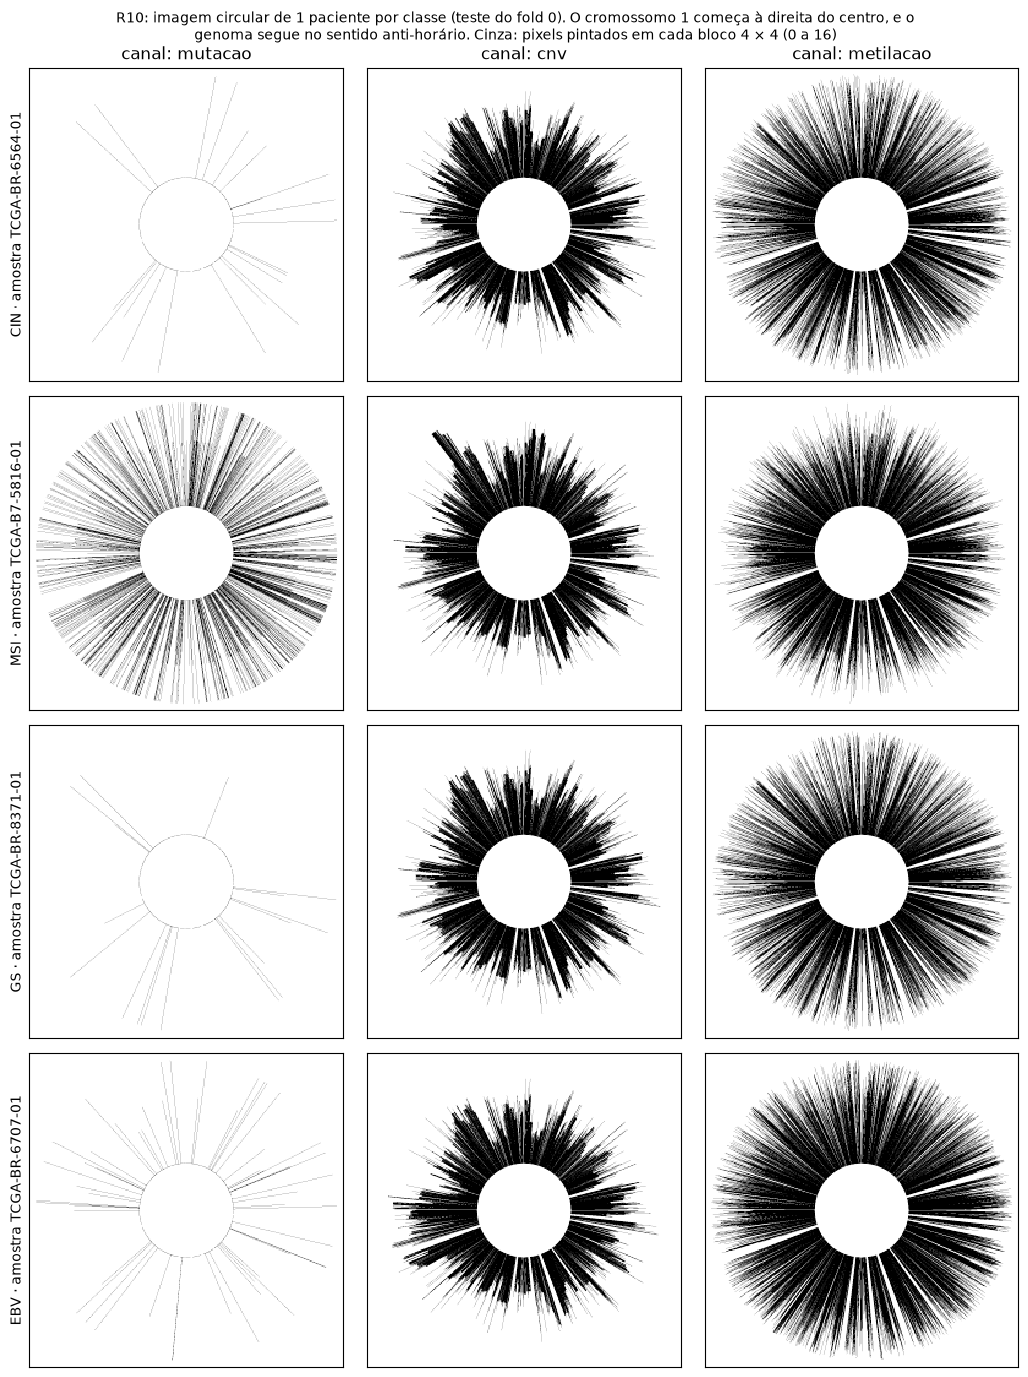

In [6]:
# um paciente de cada classe: o primeiro da classe no teste do fold 0, com a imagem do R10 desse fold
fig, eixos = plt.subplots(4, 3, figsize=(10.5, 14))
for i, classe in enumerate(CLASSES):
    j = np.flatnonzero((coorte.subtipo == classe).to_numpy() & (fold == 0))[0]
    for c, canal in enumerate(CANAIS):
        eixos[i, c].imshow(x0[j, :, :, c], cmap="Greys", vmin=0, vmax=16, interpolation="nearest")
        eixos[i, c].set(xticks=[], yticks=[])
        eixos[0, c].set_title(f"canal: {canal}")
    eixos[i, 0].set_ylabel(f"{classe.removeprefix('STAD_')} · amostra {coorte.amostra[j]}", fontsize=10)
fig.suptitle("R10: imagem circular de 1 paciente por classe (teste do fold 0). O cromossomo 1 começa à direita do centro, e o\n"
             "genoma segue no sentido anti-horário. Cinza: pixels pintados em cada bloco 4 × 4 (0 a 16)", fontsize=10)
fig.tight_layout()